<div style="background:linear-gradient(90deg,#0A6E68,#0FB9B1);padding:22px 28px;border-radius:10px;margin:18px 0 10px 0;"><h1 style="color:#ffffff;margin:0;font-weight:normal;">3. Washing-machine EDA — six households, official cleaned REFIT data</h1></div>

<div style="background:linear-gradient(90deg,#0A6E68,#0FB9B1);padding:22px 28px;border-radius:10px;margin:18px 0 10px 0;"><h2 style="color:#ffffff;margin:0;font-weight:normal;">1. Objective, selected households, mappings and periods</h2></div>

**Objective:** describe how washing machines are used (when, how often, what a cycle looks like) in six households, at **1-minute resolution**, using the official cleaned files `CLEAN_HouseN.csv`. The assignment asks for at least four households; six are enough for a comparison.

**Candidate households.** The readme lists a washing machine channel for 19 houses (House 12 has none, and there is no House 14). The channel of each house (readme appliance list) is in `CANDIDATES` below. Three of the 19 are not used:
- **House 4:** two washing machines in one house.
- **House 8:** the readme gives no make or model for the washing machine channel, and the house also has a separate washer-dryer channel. I could not verify which machine the channel measures.
- **House 13:** the readme says the machine changed on 25 Mar 2015.

Some houses also have a *washer dryer* channel. That is a different machine and is never used here. For the six houses finally selected, the readme notes no change of the washing machine.

**Selection rule** (applied in code, so the choice is reproducible and not hand-picked). Among the 16 remaining candidates keep the houses with
1. at least **400 valid days** (a valid day has at least 80% of its minutes available),
2. at least **200 detected cycles** (enough events to compare),
3. at most **5%** of minutes with the official `Issues` flag (the readme says flagged data should be discarded or noted),

then take the **six with the least missing data**. The three limits are my choices.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("dark")
pd.set_option("display.max_columns", 30)
pd.options.display.float_format = "{:,.2f}".format      # show 2 decimals and thousands commas

# washing machine column of each candidate house (readme appliance list)
CANDIDATES = {1: 5, 2: 2, 3: 6, 5: 3, 6: 2, 7: 5, 9: 3, 10: 5, 11: 3, 15: 3, 16: 5, 17: 4, 18: 5, 19: 2, 20: 4, 21: 3}

# analytical choices (explained where they are used)
MAX_FILL = 5          # minutes: longest missing gap that is filled
FROZEN_MIN = 30       # minutes: a flat stretch at least this long is "suspected frozen"
ON_WATTS = 10         # a minute is "on" above this power
MERGE_MIN = 15        # "on" periods this close together (minutes) belong to one cycle
MIN_PEAK = 1000       # a cycle must reach this power (W) at least once

**Helper functions.** They are defined here because the selection needs both of them. `prepare_house` is explained in section 2 and `find_cycles` in section 3.

In [2]:
def stretch_length(mask):
    # for every True value: the length of the stretch of consecutive True values it belongs to (0 for False)
    run_id = (mask != mask.shift()).cumsum()                    # new id each time True/False changes
    return mask.groupby(run_id).transform("size") * mask

def fill_short_gaps(s, max_len=MAX_FILL):
    # fill a NaN stretch with the last known value, but only if the WHOLE stretch is max_len minutes or less
    isna = s.isna()
    short = isna & (stretch_length(isna) <= max_len)
    return s.where(~short, s.ffill())

def valid_days(wm):
    # True for every day on which at least 80% of the minutes have a washing machine value
    return wm.notna().resample("1D").mean() >= 0.8

def prepare_house(h):
    # one row per minute: Aggregate, WM (washing machine), Issues, suspected_frozen
    path = f"../data/processed/wm_eda/house{h}_ch{CANDIDATES[h]}_fill{MAX_FILL}_frozen{FROZEN_MIN}.csv"   # name = house, channel, settings
    if os.path.exists(path):                                    # already prepared with these settings: just read it
        return pd.read_csv(path, index_col=0, parse_dates=True)

    df = pd.read_csv(f"../data/CLEAN_REFIT_081116/CLEAN_House{h}.csv")
    df["ts"] = pd.to_datetime(df["Time"])
    channels = ["Aggregate"] + [f"Appliance{i}" for i in range(1, 10)]
    minute = df.set_index("ts")[channels + ["Issues"]].resample("1min").mean()               # 1-minute mean power
    minute = minute.rename(columns={f"Appliance{CANDIDATES[h]}": "WM"})
    power = minute.drop(columns="Issues").apply(fill_short_gaps)                             # fill gaps of 5 minutes or less

    # suspected frozen: the aggregate and every other channel stay exactly the same as in the previous minute
    # that has data, for FROZEN_MIN minutes or more
    previous = power.ffill()
    steady = (previous["Aggregate"].diff() == 0) & (previous.drop(columns="Aggregate").diff().fillna(0) == 0).all(axis=1) & (power["Aggregate"] >= 10)
    suspected = steady & (stretch_length(steady) >= FROZEN_MIN)

    out = power[["Aggregate", "WM"]].copy()
    out["Issues"] = minute["Issues"]
    out["suspected_frozen"] = suspected
    out.loc[suspected, ["Aggregate", "WM"]] = np.nan                                         # excluded from the analysis

    os.makedirs("../data/processed/wm_eda", exist_ok=True)
    out.to_csv(path)
    return out

def on_periods(wm, on_watts=ON_WATTS):
    # (start, end) positions of every stretch of consecutive "on" minutes
    on = (wm.fillna(0) > on_watts).to_numpy().astype(int)
    change = np.diff(np.r_[0, on, 0])                 # +1 where "on" starts, -1 just after it ends
    starts = np.where(change == 1)[0]
    ends = np.where(change == -1)[0] - 1
    return list(zip(starts, ends))

def find_cycles(wm, on_watts=ON_WATTS, merge_min=MERGE_MIN, min_peak=MIN_PEAK):
    power = wm.to_numpy()
    merged = []
    for start, end in on_periods(wm, on_watts):
        if merged:
            gap = power[merged[-1][1] + 1:start]                       # the minutes between the previous period and this one
            if len(gap) <= merge_min and not np.isnan(gap).any():      # close enough, and no missing data in between
                merged[-1][1] = end                                    # same cycle: extend it
                continue
        merged.append([start, end])                                    # otherwise: a new cycle

    rows = []
    for start, end in merged:
        part = power[start:end + 1]
        before = power[start - 1] if start > 0 else np.nan
        after = power[end + 1] if end + 1 < len(power) else np.nan
        rows.append({"start": wm.index[start], "end": wm.index[end], "minutes": end - start + 1,
                     "peak_w": part.max(), "energy_wh": part.sum() / 60,                  # minute means in W -> Wh
                     "complete": not (np.isnan(before) or np.isnan(after))})              # False if cut by missing data
    cycles = pd.DataFrame(rows, columns=["start", "end", "minutes", "peak_w", "energy_wh", "complete"])
    cycles["is_cycle"] = cycles["peak_w"] >= min_peak
    return cycles

**Screening.** For every candidate house: valid days, share of missing minutes and number of detected cycles (rule in section 3), then the selection rule from above. **The first run takes a few minutes** because every house is read once; the prepared tables are saved in `data/processed/wm_eda/`. The file names contain the channel and the two settings (5 and 30 minutes); **if you change the code of `prepare_house`, delete that folder first**, otherwise the old files are reused.

In [3]:
screening = {}
for h, channel in CANDIDATES.items():
    m = prepare_house(h)
    screening[h] = {
        "channel": f"Appliance{channel}",
        "valid days": int(valid_days(m["WM"]).sum()),
        "% minutes missing": 100 * m["WM"].isna().mean(),
        "cycles": int(find_cycles(m["WM"])["is_cycle"].sum()),
        "% minutes with Issues flag": 100 * (m["Issues"] > 0).mean(),
    }
screening = pd.DataFrame.from_dict(screening, orient="index")
screening.index.name = "house"

screening["meets rules 1-3"] = (screening["valid days"] >= 400) & (screening["cycles"] >= 200) & (screening["% minutes with Issues flag"] <= 5)
selected = screening[screening["meets rules 1-3"]].nsmallest(6, "% minutes missing").index.tolist()
screening["selected"] = screening.index.isin(selected)

print("selected households:", selected)
screening

selected households: [19, 17, 1, 7, 15, 16]


,channel,valid days,% minutes missing,cycles,% minutes with Issues flag,meets rules 1-3,selected
house,,,,,,,
1,Appliance5,551,12.87,376,1.81,True,True
2,Appliance2,452,25.30,312,1.51,True,False
3,Appliance6,533,12.15,639,6.85,False,False
5,Appliance3,573,9.59,638,7.59,False,False
6,Appliance2,479,15.37,117,1.75,False,False
7,Appliance5,524,13.04,831,4.06,True,True
9,Appliance3,445,20.00,238,2.02,True,False
10,Appliance5,460,18.86,591,1.65,True,False
11,Appliance3,337,11.98,73,1.73,False,False


<div style="background:#E9FBFA;border-left:4px solid #0FB9B1;padding:12px 18px;border-radius:0 6px 6px 0;margin:6px 0 16px 0;color:#12312F;">Nine of the 16 candidates meet rules 1–3. The six with the least missing data are <span style="color:#0A6E68;">Houses 19, 17, 1, 7, 15 and 16</span> (7% to 19% of minutes missing). Houses 10, 9 and 2 also meet the rules but have more missing data. The last place is close: House 16 has 18.7% missing and House 10 has 18.9%, so that choice is decided by the rule, not by a clear difference in quality. The same six houses are used in every later section.</div>

<div style="background:linear-gradient(90deg,#0A6E68,#0FB9B1);padding:22px 28px;border-radius:10px;margin:18px 0 10px 0;"><h2 style="color:#ffffff;margin:0;font-weight:normal;">2. Data preparation and quality summary</h2></div>

`prepare_house` makes one table per house with one row per minute (`Aggregate`, `WM`, `Issues`, `suspected_frozen`):
1. read the official clean file and take the 1-minute **mean** power of every channel (the same resampling as in notebook 2);
2. fill gaps of **5 minutes or less** with the last known value (same function as in notebook 2); longer gaps stay missing;
3. find **suspected frozen** stretches: minutes inside a stretch of 30+ minutes in which the aggregate and every other channel stay exactly the same as in the previous minute with data. The official files were forward-filled during cleaning, so a long flat stretch may indicate a logger outage where the last value was carried forward. However, constant readings can also occur naturally, and this pattern alone cannot confirm an outage.
4. set `Aggregate` and `WM` to missing in the suspected stretches. For this usage analysis they are **excluded**, otherwise a filled outage would look like "washing machine off" or like one endless cycle.

The official `Issues` flag is **not** used to remove minutes. It is used in the selection rule and reported below; section 3.4 explains why.

Quality summary of the six selected houses:
- **valid day:** at least 80% of the minutes have a washing machine value
- **missing:** minutes without a washing machine value (outages and excluded stretches)
- **off:** the washing machine uses **10 W or less**, as a share of the minutes **with data** (missing minutes are not counted)

In [4]:
houses = {h: prepare_house(h) for h in selected}
for m in houses.values():                      # one row per minute, in time order (find_cycles relies on this)
    assert (m.index.to_series().diff().dropna() == pd.Timedelta("1min")).all()

rows = {}
for h, m in houses.items():
    wm = m["WM"]
    rows[h] = {
        "channel": f"Appliance{CANDIDATES[h]}",
        "first day": wm.dropna().index.min().date(),
        "last day": wm.dropna().index.max().date(),
        "valid days": int(valid_days(wm).sum()),
        "% minutes missing": 100 * wm.isna().mean(),
        "longest missing (days)": stretch_length(wm.isna()).max() / 1440,
        "% minutes excluded (suspected frozen)": 100 * m["suspected_frozen"].mean(),
        "% off (10 W or less)": 100 * (wm.dropna() <= 10).mean(),
        "% minutes with Issues flag": 100 * (m["Issues"] > 0).mean(),
    }
quality = pd.DataFrame.from_dict(rows, orient="index")
quality.index.name = "house"
quality

,channel,first day,last day,valid days,% minutes missing,longest missing (days),% minutes excluded (suspected frozen),% off (10 W or less),% minutes with Issues flag
house,,,,,,,,,
19,Appliance2,2014-03-06,2015-06-20,431,7.07,8.65,0.73,96.07,3.85
17,Appliance4,2014-03-06,2015-06-19,424,8.04,8.65,1.98,97.36,4.01
1,Appliance5,2013-10-09,2015-07-10,551,12.87,41.60,0.33,98.00,1.81
7,Appliance5,2013-11-01,2015-07-08,524,13.04,41.60,0.56,91.49,4.06
15,Appliance3,2013-12-17,2015-07-08,472,14.31,8.65,0.82,96.83,1.40
16,Appliance5,2014-01-10,2015-07-08,427,18.70,18.32,1.51,96.13,0.81


<div style="background:#E9FBFA;border-left:4px solid #0FB9B1;padding:12px 18px;border-radius:0 6px 6px 0;margin:6px 0 16px 0;color:#12312F;"><ul style="margin:6px 0 0 0;color:#12312F;"><li style="margin-bottom:4px;"><span style="color:#0A6E68;">Periods:</span> the households start between 2013-10-09 and 2014-03-06 and end between 2015-06-19 and 2015-07-10. Each has 424 to 551 valid days.</li>
<li style="margin-bottom:4px;"><span style="color:#0A6E68;">Missing minutes:</span> 7% (House 19) to 19% (House 16). Houses 1 and 7 both have a 41.6-day outage; the longest outage in the others is 8.65 days (Houses 15, 17, 19) and 18.3 days (House 16).</li>
<li style="margin-bottom:4px;"><span style="color:#0A6E68;">Excluded as suspected frozen:</span> 0.3% to 2.0% of the minutes.</li>
<li style="margin-bottom:4px;"><span style="color:#0A6E68;">Off time:</span> the washing machine is off (10 W or less) for 91% to 98% of the minutes with data.</li>
<li style="margin-bottom:4px;"><span style="color:#0A6E68;">Issues flag:</span> 0.8% to 4.1% of the minutes, all below the 5% limit.</li></ul></div>

<div style="background:linear-gradient(90deg,#0A6E68,#0FB9B1);padding:22px 28px;border-radius:10px;margin:18px 0 10px 0;"><h2 style="color:#ffffff;margin:0;font-weight:normal;">3. Active-cycle detection rule and detected-event counts</h2></div>

We need a rule that turns the minute-by-minute power curve into a list of cycles. It is a **heuristic**: I looked at the data to choose the numbers, but it is not a validated definition of a washing programme.

<div style="border-left:5px solid #0FB9B1;background:#E9FBFA;padding:10px 18px;border-radius:0 6px 6px 0;margin:14px 0 8px 0;"><h3 style="color:#12312F;margin:0;font-weight:normal;">3.1 When is the machine "on"?</h3></div>

All washing machine minutes above 0 W (six houses together, both axes are log scales):

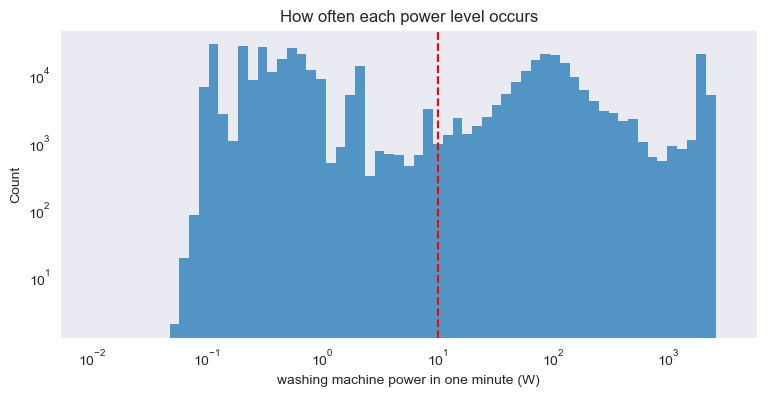

minutes at exactly 0 W: 90.6% | between 0 and 10 W: 5.3%
of the minutes above 10 W, 3.2% are 20 W or less


In [5]:
pooled = pd.concat([m["WM"] for m in houses.values()]).dropna()

fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(pooled[pooled > 0], bins=np.logspace(-2, 3.5, 66), ax=ax)
ax.set(xscale="log", yscale="log", xlabel="washing machine power in one minute (W)", title="How often each power level occurs")
ax.axvline(ON_WATTS, color="red", linestyle="--")           # the threshold that I use
plt.show()

print(f"minutes at exactly 0 W: {100 * (pooled == 0).mean():.1f}% | between 0 and 10 W: {100 * ((pooled > 0) & (pooled <= 10)).mean():.1f}%")
on = pooled[pooled > ON_WATTS]
print(f"of the minutes above {ON_WATTS} W, {100 * (on <= 20).mean():.1f}% are 20 W or less")

<div style="background:#E9FBFA;border-left:4px solid #0FB9B1;padding:12px 18px;border-radius:0 6px 6px 0;margin:6px 0 16px 0;color:#12312F;">There are two groups:
<ul style="margin:6px 0 0 0;color:#12312F;"><li style="margin-bottom:4px;"><span style="color:#0A6E68;">Very low power:</span> 90.6% of non-missing washing-machine readings are exactly 0 W, and another 5.3% are between 0 and 10 W (possibly standby power or noise; the small histogram bumps near 2 W and 8 W were not investigated).</li>
<li style="margin-bottom:4px;"><span style="color:#0A6E68;">Real activity:</span> a bump around 50–200 W and a bump around 2,000 W (my guess: drum motor and pump, and the water heater).</li></ul></div>

<div style="background:#E9FBFA;border-left:4px solid #0FB9B1;padding:12px 18px;border-radius:0 6px 6px 0;margin:6px 0 16px 0;color:#12312F;">Between about 9 W and 25 W the counts are low, and above that they rise. The red line at <span style="color:#0A6E68;">10 W</span> is placed just above the standby values. Only about 3% of the minutes above 10 W are 20 W or less, so the exact value should matter little (I did not test other values).</div>

<div style="border-left:5px solid #0FB9B1;background:#E9FBFA;padding:10px 18px;border-radius:0 6px 6px 0;margin:14px 0 8px 0;"><h3 style="color:#12312F;margin:0;font-weight:normal;">3.2 What is a cycle?</h3></div>

Some "on" periods are small blips. A washing machine may draw substantial power during its water-heating stage, so a high-power peak can help identify likely washing events. However, a high peak alone does not confirm that an event is a complete washing programme. The histogram shows the **highest power** reached in each "on" period (periods that are 15 minutes apart or less are joined first, see `find_cycles`):

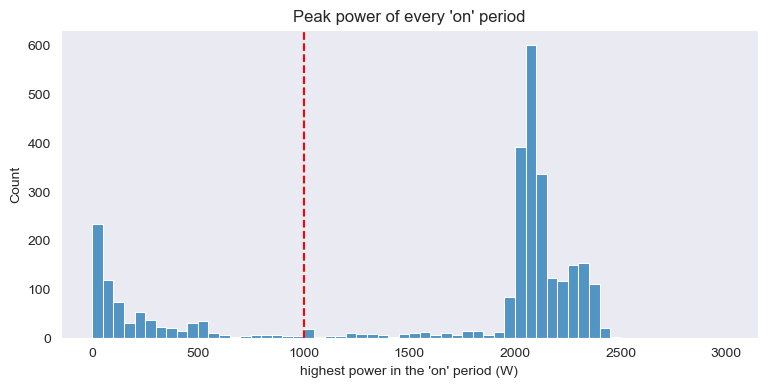

'on' periods found: 3008 | with a peak of at least 1000 W: 2277


In [6]:
events = pd.concat([find_cycles(m["WM"]).assign(house=h) for h, m in houses.items()], ignore_index=True)

fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(events["peak_w"], bins=np.arange(0, 3001, 50), ax=ax)
ax.set(xlabel="highest power in the 'on' period (W)", title="Peak power of every 'on' period")
ax.axvline(MIN_PEAK, color="red", linestyle="--")
plt.show()

print("'on' periods found:", len(events), "| with a peak of at least", MIN_PEAK, "W:", int(events["is_cycle"].sum()))

<div style="background:#E9FBFA;border-left:4px solid #0FB9B1;padding:12px 18px;border-radius:0 6px 6px 0;margin:6px 0 16px 0;color:#12312F;">The peaks form <span style="color:#0A6E68;">two groups</span>: "on" periods whose highest power stays below about 700 W (they never reach the heater range; my guess: standby blips or partial runs), and periods that mostly reach <span style="color:#0A6E68;">1,800–2,500 W</span>. Few periods lie in between, and the red line at <span style="color:#0A6E68;">1,000 W</span> sits in that sparse region. Of the 3,008 "on" periods, <span style="color:#0A6E68;">2,277</span> reach 1,000 W. The other 731 are not counted as cycles; some of them may be genuine short or cold programmes (see the limitations).</div>

<div style="border-left:5px solid #0FB9B1;background:#E9FBFA;padding:10px 18px;border-radius:0 6px 6px 0;margin:14px 0 8px 0;"><h3 style="color:#12312F;margin:0;font-weight:normal;">3.3 The rule</h3></div>

<div style="background:#E9FBFA;border-left:4px solid #0FB9B1;padding:12px 18px;border-radius:0 6px 6px 0;margin:6px 0 16px 0;color:#12312F;"><span style="color:#0A6E68;">A minute is "on" when the washing machine uses more than 10 W.</span>
<span style="color:#0A6E68;">"On" periods that are 15 minutes apart or less belong to the same cycle (if no data is missing in between).</span>
<span style="color:#0A6E68;">A detected cycle must reach at least 1,000 W at some point, using peak power as a heuristic for identifying likely washing events.</span></div>

This is a heuristic. It can **miss genuine cycles** (for example a programme that never reaches 1,000 W), and it can **join two washes** that are close together or **cut one wash in two**. So a "detected cycle" below means "an event that fits this rule", not a confirmed complete washing programme.

For every detected cycle:
- **duration** = minutes from the first to the last "on" minute (the low-power minutes between merged "on" periods are included)
- **peak power** = highest 1-minute power
- **energy (Wh)** = the sum of the 1-minute power readings (W) in the cycle **divided by 60**, because each reading is a mean power over one minute
- **complete** = the minutes just before and just after the cycle have data, so its start and end are observed

Missing data and cycle boundaries: cycles are never joined across missing minutes, so there are no missing minutes inside a cycle. A cycle next to missing data is marked incomplete and **not used for duration and energy** (it may be cut short). So the energy is **approximate, not exact**: power of 10 W or less just before the first and after the last "on" minute is not counted, and minutes filled by the 5-minute rule (section 2) use the last known value.

How much do the merge gap and the minimum peak matter? Number of detected cycles (six houses) when I change them:

In [7]:
rows = {}
for merge in (5, 15, 30):
    ev = pd.concat([find_cycles(m["WM"], merge_min=merge, min_peak=0) for m in houses.values()])
    row = {f"peak >= {p} W": int((ev["peak_w"] >= p).sum()) for p in (500, 1000, 1500)}
    ok = ev[(ev["peak_w"] >= MIN_PEAK) & ev["complete"]]                          # complete cycles, 1,000 W rule
    row["median duration (min)"] = ok["minutes"].median()
    row["median energy (Wh)"] = ok["energy_wh"].median()
    rows[f"merge gap {merge} min"] = row
pd.DataFrame.from_dict(rows, orient="index")

,peak >= 500 W,peak >= 1000 W,peak >= 1500 W,median duration (min),median energy (Wh)
merge gap 5 min,2484,2378,2299,62.00,460.31
merge gap 15 min,2364,2277,2199,64.00,479.05
merge gap 30 min,2279,2197,2120,66.00,489.38


<div style="background:#E9FBFA;border-left:4px solid #0FB9B1;padding:12px 18px;border-radius:0 6px 6px 0;margin:6px 0 16px 0;color:#12312F;">Changing <span style="color:#0A6E68;">one</span> setting changes the number of detected cycles by at most 4.4% (merge gap 5 or 30 minutes, or minimum peak 500 or 1,500 W, compared with 15 minutes and 1,000 W). Changing both at once (the corners of the table) gives up to +9% and −7%. The median duration (62 to 66 minutes) and median energy (460 to 489 Wh) of the complete cycles of the six houses together change by about 4% or less. So the main results do not depend strongly on the exact rule, but the counts are not exact.</div>

<div style="border-left:5px solid #0FB9B1;background:#E9FBFA;padding:10px 18px;border-radius:0 6px 6px 0;margin:14px 0 8px 0;"><h3 style="color:#12312F;margin:0;font-weight:normal;">3.4 Detected cycles per household</h3></div>

We keep the detected cycles of every house. We also note whether a cycle started on a **valid day**, because only valid days can be used for "how often".

In [8]:
all_cycles = []
for h, m in houses.items():
    c = find_cycles(m["WM"])
    c = c[c["is_cycle"]].copy()
    c["house"] = h
    c["date"] = c["start"].dt.normalize()
    c["valid_day"] = c["date"].map(valid_days(m["WM"])).astype(bool)
    all_cycles.append(c)
cycles = pd.concat(all_cycles, ignore_index=True)

n_valid_days = pd.Series({h: int(valid_days(m["WM"]).sum()) for h, m in houses.items()})
on_valid_days = cycles[cycles["valid_day"]].groupby("house").size()          # cycles that started on a valid day
complete = cycles[cycles["complete"]].groupby("house")                       # complete cycles only

summary = pd.DataFrame({
    "valid days": n_valid_days,
    "detected cycles": cycles.groupby("house").size(),
    "cycles per week": on_valid_days / n_valid_days * 7,                     # only cycles on valid days / valid days * 7
    "complete cycles": complete.size(),
    "median duration (min)": complete["minutes"].median(),
    "median peak (W)": complete["peak_w"].median(),
    "median energy (Wh)": complete["energy_wh"].median(),
})
summary.index.name = "house"
display(summary)

short = int((cycles["minutes"] < 10).sum())
print(f"detected cycles in total: {len(cycles)} | shorter than 10 minutes: {short} ({100 * short / len(cycles):.1f}%)")
incomplete = int((~cycles["complete"]).sum())
print(f"incomplete cycles (next to missing data, not used for duration and energy): {incomplete} ({100 * incomplete / len(cycles):.1f}%)")

# Issues flag: flagged minutes inside each detected cycle
flagged_inside = np.array([int((houses[c.house]["Issues"].loc[c.start:c.end] > 0).sum()) for c in cycles.itertuples()])
share_all = 100 * pd.concat([m["Issues"] > 0 for m in houses.values()]).mean()
print(f"Issues flag: {100 * flagged_inside.sum() / cycles['minutes'].sum():.1f}% of the minutes inside detected cycles, {share_all:.1f}% of all minutes; "
      f"{int((flagged_inside > 0).sum())} of {len(cycles)} cycles contain at least one flagged minute")

,valid days,detected cycles,cycles per week,complete cycles,median duration (min),median peak (W),median energy (Wh)
house,,,,,,,
1,551,376,4.69,360,34.00,"2,327.47",321.94
7,524,831,10.77,820,61.00,"2,082.94",551.94
15,472,255,3.53,246,93.00,"2,180.17",703.40
16,427,311,4.80,298,75.00,"2,050.62",638.66
17,424,281,4.51,277,60.00,"2,047.86",385.06
19,431,223,3.51,218,102.00,"1,840.70",249.29


detected cycles in total: 2277 | shorter than 10 minutes: 50 (2.2%)
incomplete cycles (next to missing data, not used for duration and energy): 58 (2.5%)
Issues flag: 25.1% of the minutes inside detected cycles, 2.6% of all minutes; 2169 of 2277 cycles contain at least one flagged minute


<div style="background:#E9FBFA;border-left:4px solid #0FB9B1;padding:12px 18px;border-radius:0 6px 6px 0;margin:6px 0 16px 0;color:#12312F;"><ul style="margin:6px 0 0 0;color:#12312F;"><li style="margin-bottom:4px;"><span style="color:#0A6E68;">2,277 cycles</span> were detected in the six houses.</li>
<li style="margin-bottom:4px;"><span style="color:#0A6E68;">Cycles per week</span> range from 3.5 (Houses 15 and 19) to 10.8 (House 7).</li>
<li style="margin-bottom:4px;">The <span style="color:#0A6E68;">median peak power</span> is similar in every house (1,840 to 2,330 W), but the <span style="color:#0A6E68;">median duration</span> (34 to 102 minutes) and the <span style="color:#0A6E68;">median energy</span> (249 to 703 Wh) differ a lot.</li>
<li style="margin-bottom:4px;"><span style="color:#0A6E68;">Incomplete cycles:</span> 58 of the 2,277 (2.5%) are next to missing data. They count as detected cycles but are left out of duration and energy.</li>
<li style="margin-bottom:4px;"><span style="color:#0A6E68;">Issues flag:</span> the readme says flagged data should be discarded or noted. I only <span style="color:#0A6E68;">note</span> it: 25.1% of the minutes inside detected cycles are flagged, against 2.6% of all minutes, and 2,169 of the 2,277 cycles contain at least one flagged minute. Discarding flagged minutes would remove most of the washes. I did not investigate why the flag is so frequent during cycles.</li></ul></div>

<div style="background:linear-gradient(90deg,#0A6E68,#0FB9B1);padding:22px 28px;border-radius:10px;margin:18px 0 10px 0;"><h2 style="color:#ffffff;margin:0;font-weight:normal;">4. One representative 24-hour trace</h2></div>

House 1, **2014-04-08**: a day with complete data and two detected cycles (the green bands). I chose it to show cycles clearly; House 1 averages 0.7 cycles per valid day (section 3.4), so two cycles is a busy day.

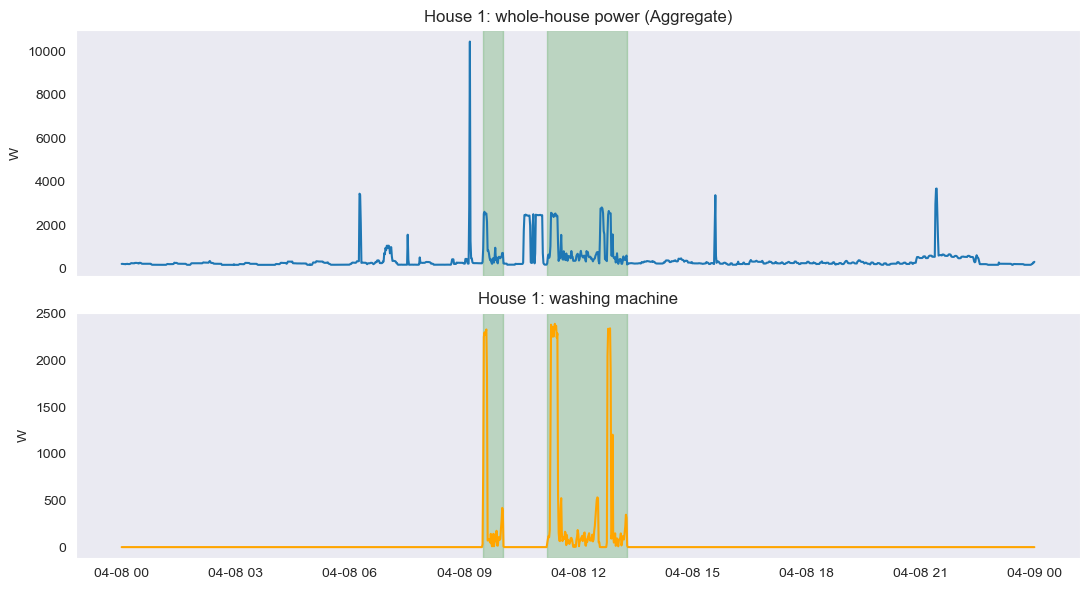

,start,end,minutes,peak_w,energy_wh
603,2014-04-08 09:29:00,2014-04-08 10:01:00,33,"2,334.00",284.02
604,2014-04-08 11:11:00,2014-04-08 13:17:00,127,"2,394.60",884.73


In [9]:
REP_HOUSE, REP_DAY = 1, "2014-04-08"
assert REP_HOUSE in houses

day = houses[REP_HOUSE].loc[REP_DAY]
assert day[["Aggregate", "WM"]].notna().all().all()                 # all 1,440 minutes have data
day_cycles = cycles[(cycles["house"] == REP_HOUSE) & (cycles["date"] == REP_DAY)]
assert len(day_cycles) == 2                                         # the day is described as having two detected cycles

fig, axes = plt.subplots(2, 1, sharex=True, figsize=(11, 6))
sns.lineplot(x=day.index, y=day["Aggregate"], ax=axes[0])
sns.lineplot(x=day.index, y=day["WM"], color="orange", ax=axes[1])
axes[0].set(title=f"House {REP_HOUSE}: whole-house power (Aggregate)", ylabel="W")
axes[1].set(title=f"House {REP_HOUSE}: washing machine", ylabel="W", xlabel="")
for _, c in day_cycles.iterrows():
    for ax in axes:
        ax.axvspan(c["start"], c["end"], color="green", alpha=0.2)
plt.tight_layout()
plt.show()

day_cycles[["start", "end", "minutes", "peak_w", "energy_wh"]]

<div style="background:#E9FBFA;border-left:4px solid #0FB9B1;padding:12px 18px;border-radius:0 6px 6px 0;margin:6px 0 16px 0;color:#12312F;"><ul style="margin:6px 0 0 0;color:#12312F;"><li style="margin-bottom:4px;"><span style="color:#0A6E68;">Aggregate (top):</span> low most of the day (mostly 200–600 W) with short spikes. The spike of about 10 kW at 09:09 is <span style="color:#0A6E68;">before</span> the first cycle, so it is another appliance.</li>
<li style="margin-bottom:4px;"><span style="color:#0A6E68;">Washing machine (bottom):</span> 0 W except in two detected cycles: <span style="color:#0A6E68;">09:29–10:01</span> (33 min, 284 Wh) and <span style="color:#0A6E68;">11:11–13:17</span> (127 min, 885 Wh). The first has about 5 minutes at 2.3 kW and then low power. The second starts with about 5 minutes of low power, then has about 12 minutes at 2.3 kW (from 11:16) and a shorter burst around 12:46–12:54.</li>
<li style="margin-bottom:4px;">The aggregate rises by about 2 kW or more when these bursts start, but other appliances also change it: for example the aggregate is at about 2.5 kW from about 10:35 to 11:03 while the washing machine is off. So <span style="color:#0A6E68;">the washing machine cannot be read from the aggregate by eye</span>. That is the disaggregation problem.</li></ul></div>

**Two detected cycles.** To see how different cycles can look, the cycle closest to the **median duration** of the house with the **shortest** median cycle and of the house with the **longest** (30 minutes of margin on each side; the green band is the detected cycle).

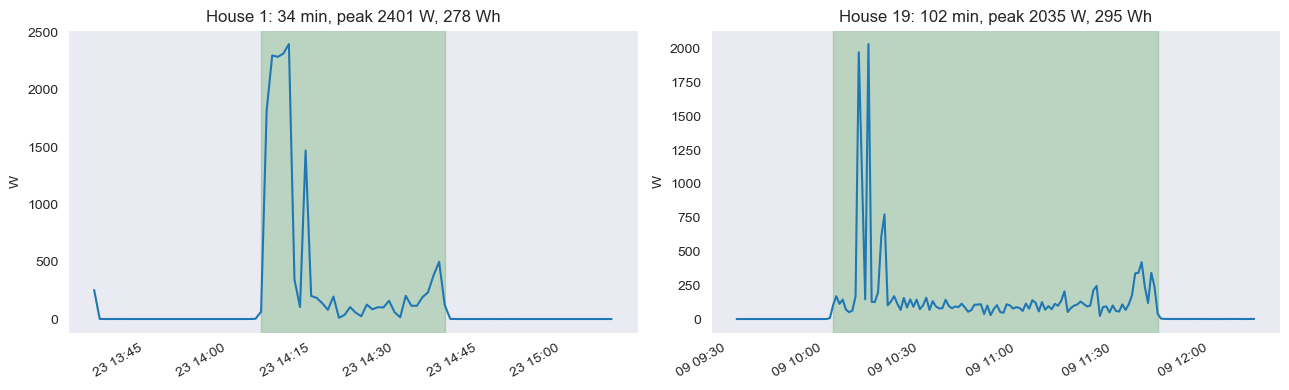

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, h in zip(axes, [summary["median duration (min)"].idxmin(), summary["median duration (min)"].idxmax()]):
    c = cycles[(cycles["house"] == h) & cycles["complete"]]
    pick = c.iloc[(c["minutes"] - c["minutes"].median()).abs().argmin()]          # the cycle closest to the median duration
    w = houses[h]["WM"].loc[pick["start"] - pd.Timedelta(minutes=30): pick["end"] + pd.Timedelta(minutes=30)]
    sns.lineplot(x=w.index, y=w.values, ax=ax)
    ax.axvspan(pick["start"], pick["end"], color="green", alpha=0.2)
    ax.set(title=f"House {h}: {pick['minutes']} min, peak {pick['peak_w']:.0f} W, {pick['energy_wh']:.0f} Wh", ylabel="W", xlabel="")
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

<div style="background:#E9FBFA;border-left:4px solid #0FB9B1;padding:12px 18px;border-radius:0 6px 6px 0;margin:6px 0 16px 0;color:#12312F;">The two cycles look different:
<ul style="margin:6px 0 0 0;color:#12312F;"><li style="margin-bottom:4px;"><span style="color:#0A6E68;">House 1</span> (34 min, 278 Wh): a burst of about 2.3 kW for 5 minutes at the start, one more short spike (about 1.5 kW), and otherwise low power (most minutes between about 30 and 270 W).</li>
<li style="margin-bottom:4px;"><span style="color:#0A6E68;">House 19</span> (102 min, 295 Wh): about 8 minutes of low power, then only 3 minutes above 1 kW (spikes near 2 kW), and otherwise low power (most minutes between about 55 and 205 W).</li></ul></div>

<div style="background:#E9FBFA;border-left:4px solid #0FB9B1;padding:12px 18px;border-radius:0 6px 6px 0;margin:6px 0 16px 0;color:#12312F;">The energy is similar although one cycle is three times as long. Both include a long low-power part because the rule counts every minute above 10 W. (My guess is that the bursts are water heating and the low power is the drum motor and pump.)</div>

<div style="background:linear-gradient(90deg,#0A6E68,#0FB9B1);padding:22px 28px;border-radius:10px;margin:18px 0 10px 0;"><h2 style="color:#ffffff;margin:0;font-weight:normal;">5. Usage by hour of day</h2></div>

When do detected cycles start? Only cycles on valid days, and only **winter** months (Nov–Feb). In these files the `Time` column equals the Unix (UTC) timestamp in every month (I checked the six houses), so I do not know if the summer hours match the UK clock. In winter UK time and UTC are the same, so the question does not matter. The price is fewer cycles.

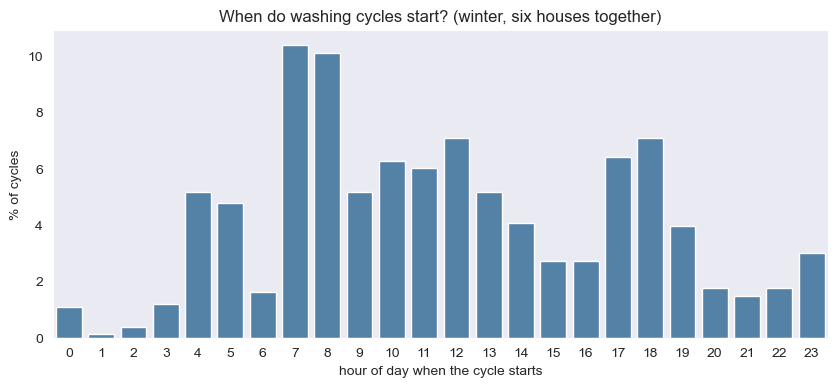

cycles used: 731 | per house: {1: 159, 7: 296, 15: 60, 16: 83, 17: 72, 19: 61}
cycles starting 07:00-08:59: 21% with all houses, 9% without House 7


In [11]:
winter = cycles[cycles["valid_day"] & cycles["start"].dt.month.isin([11, 12, 1, 2])]
by_hour = (winter["start"].dt.hour.value_counts(normalize=True) * 100).reindex(range(24), fill_value=0)

fig, ax = plt.subplots(figsize=(10, 4))
sns.barplot(x=by_hour.index, y=by_hour.values, color="steelblue", ax=ax)
ax.set(xlabel="hour of day when the cycle starts", ylabel="% of cycles", title="When do washing cycles start? (winter, six houses together)")
plt.show()

print("cycles used:", len(winter), "| per house:", winter.groupby("house").size().to_dict())
morning = lambda c: 100 * c["start"].dt.hour.isin([7, 8]).mean()
print(f"cycles starting 07:00-08:59: {morning(winter):.0f}% with all houses, {morning(winter[winter['house'] != 7]):.0f}% without House 7")

<div style="background:#E9FBFA;border-left:4px solid #0FB9B1;padding:12px 18px;border-radius:0 6px 6px 0;margin:6px 0 16px 0;color:#12312F;"><ul style="margin:6px 0 0 0;color:#12312F;"><li style="margin-bottom:4px;">The highest bars are at <span style="color:#0A6E68;">07:00 to 08:59</span> (about 10% of the cycles per hour). There are further bars around 10:00 to 13:59 (5–7% per hour) and in the evening (17:00 to 18:59, about 6–7% per hour).</li>
<li style="margin-bottom:4px;">Few cycles start between 00:00 and 03:59 (about 1% per hour or less). A small group starts at 04:00–05:59 (about 5% per hour); I did not investigate it.</li>
<li style="margin-bottom:4px;"><span style="color:#0A6E68;">Caution:</span> House 7 provides a large part of the winter cycles (see the count per house above). Without House 7 the share of cycles starting at 07:00–08:59 drops a lot, so the morning peak comes mainly from this one household. With 731 cycles from six houses, small differences between hours are not reliable.</li></ul></div>

<div style="background:linear-gradient(90deg,#0A6E68,#0FB9B1);padding:22px 28px;border-radius:10px;margin:18px 0 10px 0;"><h2 style="color:#ffffff;margin:0;font-weight:normal;">6. Usage by weekday</h2></div>

Cycles per valid day for each day of the week: all detected cycles on valid days of that weekday, divided by the number of valid days of that weekday (six houses together, so a weekday with less data is not unfairly low).

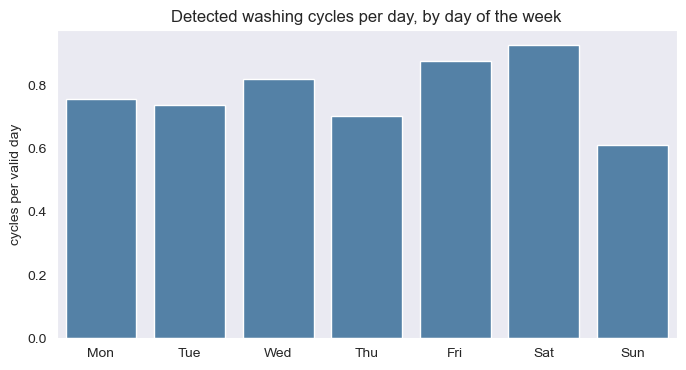

,Mon,Tue,Wed,Thu,Fri,Sat,Sun
19,0.52,0.58,0.52,0.51,0.33,0.48,0.59
17,0.65,0.78,0.66,0.68,0.48,1.05,0.20
1,0.53,0.78,0.86,0.73,0.70,0.50,0.57
7,1.75,1.14,1.52,1.01,2.23,1.95,1.19
15,0.60,0.48,0.43,0.69,0.27,0.55,0.51
16,0.32,0.59,0.78,0.52,1.08,0.97,0.49
all six,0.75,0.74,0.82,0.70,0.87,0.93,0.61


In [12]:
valid_dates = pd.concat([pd.Series(ok[ok].index) for ok in (valid_days(m["WM"]) for m in houses.values())])        # every valid day of every house
cycles_per_weekday = cycles[cycles["valid_day"]]["start"].dt.dayofweek.value_counts().sort_index()
days_per_weekday = valid_dates.dt.dayofweek.value_counts().sort_index()
by_weekday = cycles_per_weekday / days_per_weekday
by_weekday.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(x=by_weekday.index, y=by_weekday.values, color="steelblue", ax=ax)
ax.set(xlabel="", ylabel="cycles per valid day", title="Detected washing cycles per day, by day of the week")
plt.show()

# the same rate for each house separately: is the pooled pattern shared by the houses?
per_house = {}
for h, m in houses.items():
    ok = valid_days(m["WM"])
    per_house[h] = cycles[(cycles["house"] == h) & cycles["valid_day"]]["start"].dt.dayofweek.value_counts() / ok[ok].index.dayofweek.value_counts()
per_house = pd.DataFrame(per_house).sort_index().T
per_house.columns = by_weekday.index
pd.concat([per_house, by_weekday.to_frame("all six").T])

<div style="background:#E9FBFA;border-left:4px solid #0FB9B1;padding:12px 18px;border-radius:0 6px 6px 0;margin:6px 0 16px 0;color:#12312F;">Pooled over the six houses, <span style="color:#0A6E68;">Saturday</span> has the most cycles per valid day (about 0.9) and <span style="color:#0A6E68;">Sunday</span> the fewest (about 0.6). But the houses do not agree: the busiest weekday is different in most houses (table above), House 7 contributes about a third of all cycles (section 3.4), and no uncertainty is shown. So I see <span style="color:#0A6E68;">no reliable weekday pattern</span> in these data.</div>

<div style="background:linear-gradient(90deg,#0A6E68,#0FB9B1);padding:22px 28px;border-radius:10px;margin:18px 0 10px 0;"><h2 style="color:#ffffff;margin:0;font-weight:normal;">7. Cross-house comparison of cycle characteristics</h2></div>

Duration and energy of the **complete** detected cycles in each house (the box shows the middle 50% of the cycles and the line inside is the median; extreme points are hidden to keep the plot readable). The counts and the medians are in the table of section 3.4.

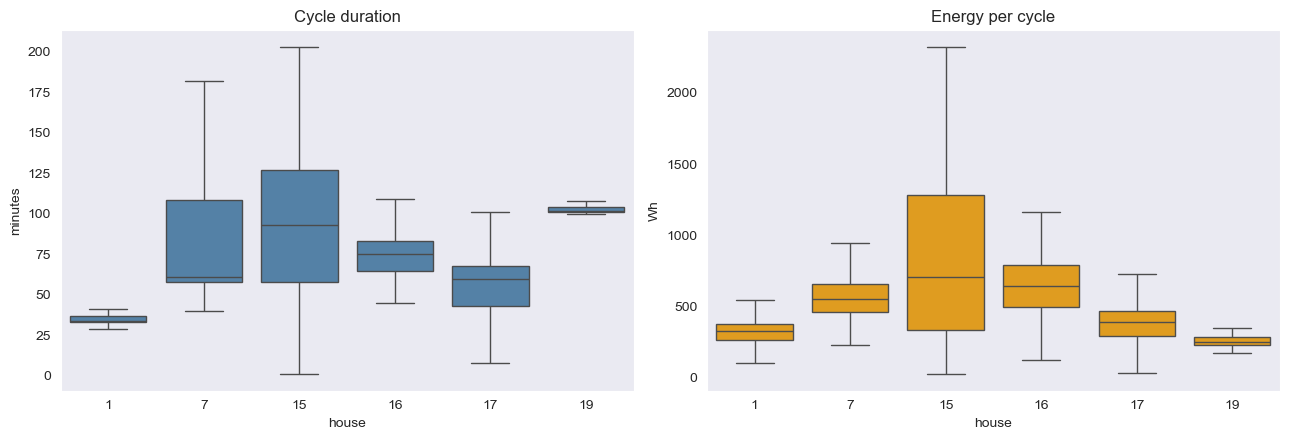

In [13]:
complete_cycles = cycles[cycles["complete"]]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.boxplot(data=complete_cycles, x="house", y="minutes", showfliers=False, color="steelblue", ax=axes[0])
axes[0].set(title="Cycle duration", ylabel="minutes")
sns.boxplot(data=complete_cycles, x="house", y="energy_wh", showfliers=False, color="orange", ax=axes[1])
axes[1].set(title="Energy per cycle", ylabel="Wh")
plt.tight_layout()
plt.show()

<div style="background:#E9FBFA;border-left:4px solid #0FB9B1;padding:12px 18px;border-radius:0 6px 6px 0;margin:6px 0 16px 0;color:#12312F;"><ul style="margin:6px 0 0 0;color:#12312F;"><li style="margin-bottom:4px;"><span style="color:#0A6E68;">Duration</span> differs between houses (median 34 minutes in House 1 to 102 in House 19). Houses 1 and 19 have <span style="color:#0A6E68;">relatively narrow boxes</span>, indicating that their detected events tend to have similar durations. This does not establish that either household uses a single washing programme, because programme information is not available in the dataset. Houses 7 and 15 have <span style="color:#0A6E68;">wide boxes</span>: very different cycle lengths; House 7's median (61 min) is close to the lower end of its box, so it seems to use both short and long programmes.</li>
<li style="margin-bottom:4px;"><span style="color:#0A6E68;">Energy per cycle</span> does not simply follow the duration: House 19 has the longest median duration but the lowest median energy (249 Wh); House 15 has the highest (703 Wh).</li>
<li style="margin-bottom:4px;">The <span style="color:#0A6E68;">peak power</span> is about the same in every house (table in section 3.4).</li>
<li style="margin-bottom:4px;">The data do not say which programme was used, so these are differences in what the machine did, not in what the household chose.</li></ul></div>

<div style="background:linear-gradient(90deg,#0A6E68,#0FB9B1);padding:22px 28px;border-radius:10px;margin:18px 0 10px 0;"><h2 style="color:#ffffff;margin:0;font-weight:normal;">8. Interpretation and limitations</h2></div>

<div style="background:#E9FBFA;border-left:4px solid #0FB9B1;padding:12px 18px;border-radius:0 6px 6px 0;margin:6px 0 16px 0;color:#12312F;"><span style="color:#0A6E68;">Rule (a heuristic):</span> a minute is "on" above <span style="color:#0A6E68;">10 W</span>; "on" periods <span style="color:#0A6E68;">15 minutes apart or less</span> are one cycle; a detected cycle must reach <span style="color:#0A6E68;">1,000 W</span> at least once.</div>

<div style="background:#E9FBFA;border-left:4px solid #0FB9B1;padding:12px 18px;border-radius:0 6px 6px 0;margin:6px 0 16px 0;color:#12312F;"><span style="color:#0A6E68;">Households and periods:</span> Houses <span style="color:#0A6E68;">1, 7, 15, 16, 17 and 19</span> (washing machine channels <span style="color:#0A6E68;">Appliance5</span>, <span style="color:#0A6E68;">5</span>, <span style="color:#0A6E68;">3</span>, <span style="color:#0A6E68;">5</span>, <span style="color:#0A6E68;">4</span>, <span style="color:#0A6E68;">2</span>), each from its first to its last day in the table of section 2 (between 2013-10-09 and 2015-07-10).</div>

<div style="background:#E9FBFA;border-left:4px solid #0FB9B1;padding:12px 18px;border-radius:0 6px 6px 0;margin:6px 0 16px 0;color:#12312F;"><span style="color:#0A6E68;">Main findings</span>
<ul style="margin:6px 0 0 0;color:#12312F;"><li style="margin-bottom:4px;">2,277 cycles were detected, 3.5 to 10.8 per week per household.</li>
<li style="margin-bottom:4px;">In winter the pooled start times peak at 07:00–08:59, but this is mostly one household (House 7). The weekday pattern is not consistent between houses. With six households I would not call either a general pattern.</li>
<li style="margin-bottom:4px;">The peak power is similar (about 2 kW), while duration (34 to 102 min) and energy (249 to 703 Wh) vary between households.</li></ul></div>

<div style="background:#E9FBFA;border-left:4px solid #0FB9B1;padding:12px 18px;border-radius:0 6px 6px 0;margin:6px 0 16px 0;color:#12312F;"><span style="color:#0A6E68;">Limitations</span>
<ul style="margin:6px 0 0 0;color:#12312F;"><li style="margin-bottom:4px;"><span style="color:#0A6E68;">The rule is a heuristic.</span> It can miss genuine cycles (for example a programme that never reaches 1,000 W), join two close washes or cut one in two. Some detected events are very short (see the count in section 3.4), so they are probably not full washes.</li>
<li style="margin-bottom:4px;"><span style="color:#0A6E68;">Frozen readings.</span> The official files are forward-filled, so outages can look like real data. I excluded stretches of 30+ minutes in which every channel stayed exactly the same (0.3% to 2.0% of the minutes). The 30 minutes is a judgement, and other stalls may remain.</li>
<li style="margin-bottom:4px;"><span style="color:#0A6E68;">Missing data.</span> 7% to 19% of the minutes are missing; all "per week" and weekday rates use valid days only, but a valid day can still miss up to 20% of its minutes, and a cycle next to a gap can be cut or missed. Cycles next to missing data are marked incomplete and left out of duration and energy.</li>
<li style="margin-bottom:4px;"><span style="color:#0A6E68;">Energy is approximate.</span> It is the sum of 1-minute mean powers divided by 60; power of 10 W or less just outside a cycle is not counted, and filled minutes use the last known value.</li>
<li style="margin-bottom:4px;"><span style="color:#0A6E68;">Issues flag.</span> Flagged minutes are kept, not removed, because most detected cycles contain flagged minutes (section 3.4). I did not investigate why; the flag compares the sub-meters with the aggregate, not the washing machine alone.</li>
<li style="margin-bottom:4px;"><span style="color:#0A6E68;">Clock.</span> The hour-of-day plot uses winter only, because the <span style="color:#0A6E68;">Time</span> column equals UTC in every month and I do not know if summer hours match the UK clock.</li>
<li style="margin-bottom:4px;"><span style="color:#0A6E68;">Small sample.</span> Six UK households, 2013–2015. The results are descriptive and should not be generalised; House 7 alone contributes about a third of the detected cycles.</li></ul></div>